# Foundation 1: Spatial Canvas & Infrastructure EDA
**Objective:** Ingest the raw OpenCellID cell registry, check it against Kenya's national border, profile the radio technologies and network operators, and cluster co-located cells into approximate physical sites. The result is the **infrastructure layer** (the supply side) of the whole study.

| | |
|---|---|
| **Pipeline** | **01 Spatial canvas** → 02 Temporal extraction → 03 Spatial downscale → 04 MTL engine → 05 Explainability & NDS |
| **Answers** | Research Question 1 and the first half of Specific Objective 1 (the spatial infrastructure layer) |
| **Input** | `Data/raw_spatial/keCellTowers.csv` (OpenCellID export for MCC 639, Kenya) |
| **Outputs** | `Data/processed/cells_clean.parquet`, `Data/processed/sites_all_technologies.csv`; Tables 4.1–4.2; Figures 4.1–4.2 |

Shared paths, constants and helper functions live in `project_config.py`, so every notebook uses the same settings.

**The idea in one paragraph.** To find where mobile data demand may outgrow the network, the study needs a **demand** layer (how much data is used, and where) and a **supply** layer (where the network's capacity sits). This notebook builds the supply layer: it cleans a list of individual radio cells and groups them into approximate masts ("sites"). Notebook 03 then adds up the cells of each sub-county into a capacity proxy, divides the sub-county's demand by it, and builds the stress label from that load-to-capacity ratio.

**Key terms**
- **OpenCellID:** a free, crowdsourced database of mobile-network cells. Phones running contributing apps report the cell they are connected to together with their GPS position, and OpenCellID estimates each cell's location from these reports, so positions are approximate.
- **Logical cell:** one row of the registry, i.e. one radio cell of one operator on one technology (for example one sector of a 3G antenna). **Physical site:** a mast or rooftop, which usually carries several logical cells, so cells have to be grouped to recover sites (Step 4).
- **EDA (exploratory data analysis):** checking and describing the data with counts, tables and plots before any modelling.

**Layout:** Step 1 loads and cleans the registry; Step 2 counts cells by technology and operator (Table 4.1); Step 3 dates the records (Figure 4.1); Step 4 groups cells into sites (Table 4.2); Step 5 describes and maps the sites (Figure 4.2); Step 6 checks how well each sub-county is recorded; Step 7 saves the results.

**Setup (next cell).** `from project_config import *` loads the libraries pandas (`pd`), NumPy (`np`) and Matplotlib (`plt`), the folder paths, the study constants (such as `CLUSTER_EPS_M = 100`) and the helper functions (such as `in_kenya`, `save_table` and `save_figure`). Run it first; every later cell relies on these names.

In [1]:
# Load the shared settings: pandas (pd), NumPy (np), Matplotlib (plt), the folder paths, the
# study constants and the helper functions, all defined once in project_config.py.
from project_config import *
# DBSCAN (from scikit-learn) groups points that lie close together. Step 4 uses it to find
# groups of connected cells before the complete-linkage clustering.
from sklearn.cluster import DBSCAN
import warnings
# Hide warning messages (for example notices about future library changes) so the output stays
# readable. This only changes what is shown on screen, not any result.
warnings.filterwarnings('ignore')
# Fix the random-number generators (helper in project_config.py) so re-runs give identical
# results. No step in this notebook draws random numbers; the call is a consistency habit.
set_seeds(42)

## Step 1: Load the Registry and Check the National Border
OpenCellID is crowdsourced, so a few records can be mislocated. Cells are kept only if they fall inside Kenya, tested with the IANA time-zone polygons bundled in `timezonefinder` (Kenya is the only country in the `Africa/Nairobi` zone, and the polygons follow OpenStreetMap national borders). The same test is used for the Ookla tiles in Notebook 02.

The other quality checks named in the proposal (Section 3.3.3) are run and reported below. Duplicates and missing radio types are removed if any exist. Location confidence is **reported, not filtered**: every record is an estimated position (`changeable = 1`) and about half rest on a single sample, so a confidence filter would remove half the layer, mostly in rural areas. This is declared as a deviation.

One sub-county is spelled two ways in the registry (`AINAMOI` and `Ainamoi Sub County`, both in Kericho), which would otherwise create a spurious extra unit. The two spellings are harmonised. Of the five nearest other cells around each of the 29 affected cells, 119 of 145 are in Ainamoi and 26 in Belgut, which supports the merge.

**Why it matters.** Every later step adds up cells by sub-county. A cell in the wrong country, counted twice, or filed under a misspelt sub-county would distort that sub-county's capacity or create a fake extra unit in the panel.

**Registry columns used here**
- `radio`: technology of the cell: GSM (2G), UMTS (3G), LTE (4G) or NR (5G).
- `mcc`, `net`: Mobile Country Code (639 is Kenya) and Mobile Network Code, which identifies the operator (Step 2).
- `area`, `cell`: location-area (for LTE, tracking-area) code and cell number. With `radio`, `mcc` and `net` they identify one cell uniquely.
- `lat`, `lon`: estimated position in decimal degrees. `samples`: number of measurements behind that estimate. `changeable`: 1 if OpenCellID calculated the position from measurements, 0 if it is an exact position.
- `created`, `updated`: first and last record dates (Step 3). `county`, `subcounty`, `ward`: the administrative units supplied with each cell.

**How the code does it.** `in_kenya()` (from `project_config.py`) returns True or False for each row, and `df_raw[inside]` uses it as a **boolean mask** that keeps only the True rows. `duplicated()` is run on all columns (exact copies) and on the five identifier columns (the same cell listed twice); `drop_duplicates()` and `dropna()` then remove any such rows. `.replace()` changes the spelling `AINAMOI` to `Ainamoi Sub County`.

In [2]:
# Read the raw OpenCellID export into a DataFrame (a table with named columns). RAW_SPATIAL is
# the folder 'Data/raw_spatial/' from project_config.py; '+' joins it to the file name.
df_raw = pd.read_csv(RAW_SPATIAL + 'keCellTowers.csv')
# Border test: one True (inside Kenya) or False (outside) per row, as a NumPy array.
inside = in_kenya(df_raw['lat'], df_raw['lon'])
# f-string: each {...} is replaced by its value. ':,' adds thousands separators (12,345).
print(f"Logical cells in the export: {len(df_raw):,}")
# '~' flips True and False, so ~inside marks the cells outside; .sum() counts the Trues.
print(f"Cells located outside Kenya's border (removed): {(~inside).sum()}")
# Boolean mask: keep only the rows where 'inside' is True. .copy() makes an independent table,
# so later changes to 'cells' can never alter df_raw.
cells = df_raw[inside].copy()

# quality checks from proposal Section 3.3.3
# (1) rows identical in every column; (2) the same cell identifier
# (radio + country code + network code + area + cell) appearing again; (3) missing radio type.
# .isna() is True where a value is missing.
n_dup = cells.duplicated().sum()
n_key = cells.duplicated(['radio', 'mcc', 'net', 'area', 'cell']).sum()
n_noradio = cells['radio'].isna().sum()
print(f"Exact duplicate rows: {n_dup} | duplicate cell identifiers: {n_key} | missing radio type: {n_noradio}")
# Remove repeated identifiers (the first copy is kept) and rows with no radio type. The two
# methods are chained: the table returned by the first is passed straight to the second.
cells = cells.drop_duplicates(['radio', 'mcc', 'net', 'area', 'cell']).dropna(subset=['radio'])
# Location confidence. (cells['samples'] <= 1) is True/False per cell; its mean is the share
# of Trues. ':.1%' prints a share as a percentage with 1 decimal (0.25 -> 25.0%).
print(f"Location confidence (reported, not filtered): {(cells['samples'] <= 1).mean():.1%} of cells rest on one sample; "
      f"{(cells['changeable'] == 1).mean():.0%} are estimated positions (changeable = 1)")

# one sub-county spelled two ways in the registry
# Count the cells with the variant spelling first, so the change can be reported.
n_ain = (cells['subcounty'] == 'AINAMOI').sum()
# .replace({old: new}) swaps the variant for the standard spelling; other names stay unchanged.
cells['subcounty'] = cells['subcounty'].replace({'AINAMOI': 'Ainamoi Sub County'})
print(f"Harmonised sub-county name: {n_ain} cells 'AINAMOI' -> 'Ainamoi Sub County'")
# .nunique() counts the distinct values in a column (here: distinct counties and sub-counties).
print(f"Cells kept: {len(cells):,} in {cells['county'].nunique()} counties and {cells['subcounty'].nunique()} sub-counties")

Logical cells in the export: 78,730
Cells located outside Kenya's border (removed): 8


Exact duplicate rows: 0 | duplicate cell identifiers: 0 | missing radio type: 0
Location confidence (reported, not filtered): 48.1% of cells rest on one sample; 100% are estimated positions (changeable = 1)
Harmonised sub-county name: 29 cells 'AINAMOI' -> 'Ainamoi Sub County'
Cells kept: 78,722 in 47 counties and 294 sub-counties


**How to read the output.**
- The first two lines give the size of the raw file and how many cells fell outside the border. A small number of removals is normal for crowdsourced data; a large number would point to a coordinate problem (for example latitude and longitude swapped).
- The duplicate and missing-radio counts should ideally be 0. Any non-zero count is removed by the code, so these numbers document the check.
- The location-confidence line is reported for transparency only (see the deviation note above).
- The harmonisation line should report the 29 `AINAMOI` cells. In the last line, Kenya has 47 counties, which makes the county count a quick sanity check, and the sub-county count (294 after the merge) is the number of spatial units used in the rest of the study.

## Step 2: Radio Technologies and Network Operators
The `net` column holds the Mobile Network Code (MNC). It is mapped to the Kenyan operators (Safaricom, Airtel, Telkom Kenya, Jamii/Faiba).

**All radio technologies are kept.** An earlier version of this pipeline kept only LTE and NR cells. That left only 2,372 cells, because the registry contains **no NR (5G) cells** at all, and it hid the 2G/3G-only sites that are exactly the candidates for an LTE / 5G Non-Standalone upgrade. GSM and UMTS cells are therefore part of the capacity layer, with lower capacity weights (Notebook 03).

**Key terms**
- **MCC and MNC:** a mobile network is identified by a Mobile Country Code (MCC, 639 for Kenya) plus a Mobile Network Code (MNC) for the operator. One operator can hold several MNCs, which is why `OPERATOR_MAP` in `project_config.py` lists two codes each for Safaricom and Airtel.
- **GSM, UMTS, LTE, NR:** the 2G, 3G, 4G and 5G radio technologies. Each newer generation carries much more data per cell, hence the larger capacity weights (`TECH_W`) in Notebook 03.
- **5G Non-Standalone (NSA):** 5G introduced alongside an existing LTE network, which handles the connection set-up and provides the core network. A site with LTE is the natural starting point for 5G; a 2G/3G-only site needs LTE first.

**How the code does it.** `.map(OPERATOR_MAP)` looks up each MNC in the dictionary; codes not in it become missing (`NaN`) and `.fillna('Other')` labels them "Other". `pd.crosstab()` counts the cells for every pair of radio type (rows) and operator (columns), with *Total* margins, and `.reindex()` puts the rows in generation order.

In [3]:
# Translate each Mobile Network Code into an operator name. .map(dict) looks each value up in
# the dictionary; codes that are not listed become NaN (missing), and .fillna() labels them.
cells['operator'] = cells['net'].map(OPERATOR_MAP).fillna('Other')
# Cross-tabulation: the number of cells for each (radio type, operator) pair. margins=True adds
# row and column totals, and margins_name gives them the label 'Total'.
t41 = pd.crosstab(cells['radio'], cells['operator'], margins=True, margins_name='Total')
# Order the rows from 2G to 4G, then Total. reindex keeps only the listed rows, so a type not
# in the list (such as NR) would not appear; the NR count is printed separately below.
t41 = t41.reindex(['GSM', 'UMTS', 'LTE', 'Total'])
print("Table 4.1: OpenCellID logical cells by radio technology and operator (inside Kenya)")
# save_table() writes the CSV and returns the same table; display() is Jupyter's way of showing
# a DataFrame as a formatted table. index=True keeps the radio labels (row names) in the CSV.
display(save_table(t41, '4.01', 'cells_by_radio_operator', index=True))
# Count the 5G (NR) cells: the comparison is True/False per cell and .sum() counts the Trues.
print(f"NR (5G) cells in the registry: {(cells['radio'] == 'NR').sum()}")

Table 4.1: OpenCellID logical cells by radio technology and operator (inside Kenya)
[saved] Outputs/tables/T4.01_cells_by_radio_operator.csv


operator,Airtel,Jamii (Faiba),Other,Safaricom,Telkom Kenya,Total
radio,,,,,,
GSM,5517,11,15,21589,3738,30870
UMTS,6543,9,9,36238,2681,45480
LTE,2,0,0,2365,5,2372
Total,12062,20,24,60192,6424,78722


NR (5G) cells in the registry: 0


**How to read Table 4.1.** Each number is a count of **logical cells**, not sites. Read across a row for how one technology is split between operators, and down a column for one operator's mix of technologies. The *Total* column and row give the cells per technology and per operator, and the bottom-right number is all cells kept in Step 1. *Other* collects MNCs not listed in `OPERATOR_MAP`; a small *Other* column means almost every cell has a known operator. The NR line confirms that the study cannot observe existing 5G capacity and works from the GSM, UMTS and LTE layers.

## Step 3: How Recent Is the Registry?
The `created` and `updated` fields are Unix timestamps. They show **when** the infrastructure was observed, which matters because the demand data (Notebook 02) run from 2022 to 2026.

A **Unix timestamp** counts the seconds since 1 January 1970 (UTC). `created` is when OpenCellID first recorded the cell and `updated` is when its record was last refreshed. `pd.to_datetime(..., unit='s')` turns them into dates, and Figure 4.1 counts the cells per calendar year, once by year created and once by year last updated.

created: 2008-10 to 2019-01
updated: 2008-10 to 2019-01


[saved] Outputs/figures/F4.01_opencellid_record_dates.png


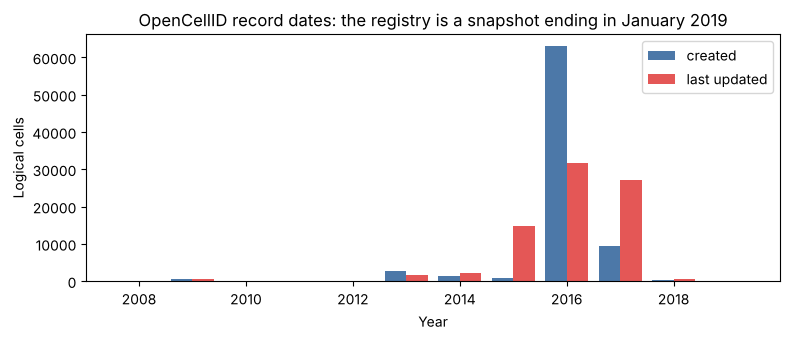

In [4]:
# Convert Unix timestamps (seconds since 1 January 1970) into pandas dates.
created = pd.to_datetime(cells['created'], unit='s')
updated = pd.to_datetime(cells['updated'], unit='s')
# ':%Y-%m' inside the braces formats a date as year-month, for example 2019-01.
print(f"created: {created.min():%Y-%m} to {created.max():%Y-%m}")
print(f"updated: {updated.min():%Y-%m} to {updated.max():%Y-%m}")

# Figure 4.1: plt.subplots creates a figure and one set of axes (ax), 8 x 3.5 inches.
fig, ax = plt.subplots(figsize=(8, 3.5))
# One bin per calendar year. .dt.year extracts the year from each date. np.arange(a, b + 2)
# lists the years a ... b + 1; subtracting 0.5 puts the bin edges half-way between years, so
# each bar is centred on a whole year.
bins = np.arange(created.dt.year.min(), updated.dt.year.max() + 2) - 0.5
# Passing a list of two series draws them as side-by-side bars within each bin.
ax.hist([created.dt.year, updated.dt.year], bins=bins, label=['created', 'last updated'], color=['#4c78a8', '#e45756'])
# ';' allows two short statements on one line.
ax.set_xlabel('Year'); ax.set_ylabel('Logical cells')
ax.set_title('OpenCellID record dates: the registry is a snapshot ending in January 2019')
# tight_layout() adjusts the spacing so that no label is cut off.
ax.legend(); plt.tight_layout()
# Save as Outputs/figures/F4.01_opencellid_record_dates.png first, because plt.show() displays
# the figure and then clears it.
save_figure('4.01', 'opencellid_record_dates'); plt.show()

**How to read Figure 4.1.** Each year has two bars: blue counts the cells first recorded that year, red counts the cells last updated that year. What matters is where the bars stop. If the registry were current, the red bars would reach into the 2022–2026 demand period; instead they stop at the last month printed above.

**Data caveat carried through the study:** the registry is a **2019 snapshot**. Infrastructure is therefore treated as a static baseline. All variation over time comes from the demand side: the Ookla data set **where** demand sits each quarter, and the CA national series sets **how large** the total is (Notebook 03 shows that the stress label depends only on the first). A fresh OpenCellID download would let capacity vary over time as well (a limitation for Chapter 5).

## Step 4: From Logical Cells to Approximate Physical Sites
Several sectors and carriers on one mast share nearly the same coordinates, so logical cells are grouped into **approximate sites**. The proposal (Section 3.3.3) asks for cells "within a defined distance" to be grouped and for several thresholds to be tested. The **100 m threshold is this study's choice**; Table 4.2 compares 50, 75, 100 and 125 m.

Cells are grouped by position only, regardless of operator or radio type. Shared masts carrying several operators and technologies are common, and the number of operators is kept as a site attribute. The sub-county capacity proxy (Notebook 03) adds up cells, so this choice does not change it.

**Method: complete-linkage clustering.** Every cell in a site is within 100 m of **every other** cell in that site, so no two cells of one site are more than 100 m apart. Simpler rules fail in dense cities:
- Snapping to a 100 m grid (the first version) splits a mast that sits on a grid line.
- DBSCAN with `min_samples = 1` is *single* linkage. It joins any two cells less than 100 m apart, so chains of cells grow into "sites" that cover several kilometres of Nairobi (first row of Table 4.2).

For speed, the complete-linkage step runs separately inside each group of cells that are connected at 100 m (found with DBSCAN). A complete-linkage cluster can never span two such groups, so the result is identical to clustering all cells at once.

**Key terms**
- **Haversine distance:** the distance between two points along the Earth's surface, computed from their latitudes and longitudes (which are angles, not metres).
- **Single linkage** joins two groups if *any* cell of one is within the threshold of *any* cell of the other. **Complete linkage** joins them only if *every* pair of cells is within the threshold, so the largest distance inside a site never exceeds it.
- **DBSCAN** links points within a distance `eps` of each other; a point needs `min_samples` points nearby (itself included) to start or extend a group. With `min_samples = 1` groups grow through any chain of close neighbours, which is single linkage.

**A made-up example.** Cells A, B and C lie on a line, 80 m from A to B and 80 m from B to C, so A and C are 160 m apart. Single linkage puts all three into one site because each step is under 100 m. Complete linkage cannot, because A and C are more than 100 m apart, so one of the three ends up in a separate site. In a dense city such chains can run on for kilometres.

**How the code does it.** `single_linkage(eps_m)` gives each cell a connected-group number with DBSCAN. `cluster_sites(eps_m)` takes one group at a time, converts its coordinates to metres on a flat local map, and runs complete linkage (`pdist`, `linkage`, `fcluster`) cut at `eps_m`. `describe()` turns the result into one row of Table 4.2. The loop runs 50, 75, 100 and 125 m and stores the 100 m result (`CLUSTER_EPS_M`) as `cells['site_id']`, which every later step uses.

In [5]:
# SciPy's hierarchical (tree-based) clustering: linkage() builds the tree of merges and
# fcluster() cuts it into clusters. pdist() computes the distance between every pair of points.
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist

# The haversine distance in scikit-learn expects [latitude, longitude] in radians, not degrees.
# Double brackets select two columns; .values turns them into a plain NumPy array.
coords_rad = np.radians(cells[['lat', 'lon']].values)
# The same coordinates in degrees as two separate arrays (tuple unpacking: a, b = x, y).
lat, lon = cells['lat'].values, cells['lon'].values

def single_linkage(eps_m):
    """DBSCAN with min_samples = 1: connected groups of cells closer than eps_m (single linkage)."""
    # Haversine distances come out as angles in radians (distance / Earth radius), so the
    # threshold in metres is divided by EARTH_R. min_samples=1: no cell is left out as 'noise'.
    # 'ball_tree' is a fast neighbour-search index that works with the haversine distance.
    # fit_predict() returns one group number per cell.
    return DBSCAN(eps=eps_m / EARTH_R, min_samples=1, metric='haversine', algorithm='ball_tree').fit_predict(coords_rad)

def cluster_sites(eps_m):
    """Complete linkage with a maximum within-site distance of eps_m metres."""
    # Connected groups at eps_m. A complete-linkage site can never span two groups, so each
    # group can be clustered on its own, which is much faster than all cells at once.
    groups = single_linkage(eps_m)
    # labels: an empty integer array, to be filled with one site number per cell.
    # nxt: the next site number not yet used.
    labels, nxt = np.empty(len(groups), dtype=np.int64), 0
    # Row positions sorted by group number, so the cells of each group sit next to each other.
    # kind='stable' keeps the original order of the cells within a group.
    order = np.argsort(groups, kind='stable')
    # Cut the sorted positions wherever the group number changes: np.diff() is non-zero at
    # a change, np.flatnonzero() returns those positions, +1 marks where the next group starts.
    # Each 'grp' is then the array of row positions of one connected group.
    for grp in np.split(order, np.flatnonzero(np.diff(groups[order])) + 1):
        # A single isolated cell is a site on its own; 'continue' jumps to the next group.
        if len(grp) == 1:
            labels[grp] = nxt; nxt += 1
            continue
        # Convert degrees to metres on a flat map centred on the group's mean latitude:
        # x = east-west metres (a degree of longitude shrinks by cos(latitude)),
        # y = north-south metres. np.c_[a, b] stacks two arrays as columns (an n x 2 array).
        lat0 = np.radians(lat[grp].mean())            # local projection in metres (accurate over a few km)
        xy = np.c_[EARTH_R * np.cos(lat0) * np.radians(lon[grp]), EARTH_R * np.radians(lat[grp])]
        # pdist(xy): distance between every pair of cells in the group.
        # linkage(method='complete'): repeatedly merge the two clusters whose farthest pair of
        # cells is closest. fcluster(t=eps_m, criterion='distance'): cut the tree so that no
        # two cells in a cluster are more than eps_m metres apart. Numbers start at 1.
        sub = fcluster(linkage(pdist(xy), method='complete'), t=eps_m, criterion='distance')
        # Shift the group's own numbers (1, 2, ...) to unused national numbers (nxt, nxt + 1,
        # ...), then move nxt past them, so every site number is unique across Kenya.
        labels[grp] = nxt + sub - 1; nxt += sub.max()
    return labels

# Summarise one clustering result (lab = one site number per cell) as one row of Table 4.2.
def describe(lab, method, eps_m):
    # value_counts() counts how often each site number occurs, i.e. the cells per site.
    size = pd.Series(lab).value_counts()
    # For every site, the smallest and largest latitude and longitude of its cells.
    # .agg(['min', 'max']) gives two-level column names such as ('lat', 'max').
    ext = pd.DataFrame({'s': lab, 'lat': lat, 'lon': lon}).groupby('s').agg(['min', 'max'])
    # Diagonal of each site's bounding box in metres. One degree of latitude is about
    # 111,320 m; a degree of longitude is shorter by the factor cos(latitude).
    # np.hypot(a, b) = sqrt(a² + b²). 111_320 is 111320 ('_' is a digit separator).
    extent = np.hypot((ext['lat']['max'] - ext['lat']['min']) * 111_320,
                      (ext['lon']['max'] - ext['lon']['min']) * 111_320 * np.cos(np.radians(ext['lat']['min'])))
    # One table row as a dictionary {column name: value}.
    return {'Method': method, 'Max within-site distance (m)': eps_m, 'Approximate sites': len(size),
            'Mean cells per site': size.mean(), 'Max cells per site': size.max(),
            'Largest site bounding-box diagonal (m)': extent.max(), 'Single-cell sites (%)': 100 * (size == 1).mean()}

# First row of Table 4.2: single linkage at 100 m, shown only for comparison.
rows = [describe(single_linkage(CLUSTER_EPS_M), 'Single linkage (DBSCAN), not used', CLUSTER_EPS_M)]
# Complete linkage at four thresholds; CLUSTER_EPS_M (100 m) is the one used by the study.
# pdist stores one distance per pair of cells, so memory grows with the square of group size.
for eps_m in [50, 75, CLUSTER_EPS_M, 125]:      # larger thresholds need several GB of memory for the densest Nairobi groups
    lab = cluster_sites(eps_m)
    # 'A' + ('B' if condition else '') appends ' (used)' to the label of the 100 m row only.
    rows.append(describe(lab, 'Complete linkage' + (' (used)' if eps_m == CLUSTER_EPS_M else ''), eps_m))
    # Keep the 100 m site numbers as each cell's site_id for the rest of the pipeline.
    if eps_m == CLUSTER_EPS_M:
        cells['site_id'] = lab
# A list of dictionaries becomes a DataFrame with one row per dictionary; round to 2 decimals.
t42 = pd.DataFrame(rows).round(2)
print("Table 4.2: Grouping logical cells into approximate sites: method and distance threshold")
display(save_table(t42, '4.02', 'site_clustering_sensitivity'))

Table 4.2: Grouping logical cells into approximate sites: method and distance threshold
[saved] Outputs/tables/T4.02_site_clustering_sensitivity.csv


,Method,Max within-site distance (m),Approximate sites,Mean cells per site,Max cells per site,Largest site bounding-box diagonal (m),Single-cell sites (%)
0,"Single linkage (DBSCAN), not used",100,33570,2.35,8998,11688.48,74.75
1,Complete linkage,50,49290,1.60,56,63.88,75.11
2,Complete linkage,75,44922,1.75,62,100.35,69.80
3,Complete linkage (used),100,40724,1.93,67,131.80,65.42
4,Complete linkage,125,37784,2.08,67,168.80,62.42


**Reading Table 4.2:** single linkage creates "sites" several kilometres wide in Nairobi, which would hand the capacity of a whole district to one sub-county. Complete linkage keeps every pair of cells in a site within the threshold. A site's bounding box can still be slightly wider than 100 m along its diagonal (last-but-one column), because the box corners are not cells. The site count falls as the threshold grows. The sub-county capacity proxy (Notebook 03) adds up **cells**, not sites, so the threshold mainly affects the number of sites and which site each Ookla tile is assigned to.

**The columns.** *Approximate sites* is how many sites a method produces (fewer means more merging). *Mean* and *Max cells per site* give the typical and largest site; a real mast carries a limited number of cells, so a very large maximum signals chaining. *Largest site bounding-box diagonal* is the widest site; under complete linkage it can be at most about 1.4 times the threshold (the diagonal of a square whose sides equal the threshold), while a value in kilometres means distant cells were joined. *Single-cell sites (%)* falls as the threshold grows, because more cells find a partner close enough to join.

**What a good result looks like:** for the chosen method the widest site stays close to the threshold and the largest site is plausible for one mast. If the site count also changes gradually between neighbouring thresholds, 100 m is not a knife-edge choice.

## Step 5: Site Attributes
Each site keeps its mean position, its cell counts by technology, the number of operators present, and the most common county and sub-county of its cells. The **highest technology** at each site (LTE > UMTS > GSM) is used for mapping and, later, for the recommended screening action.

**Why it matters.** Notebook 03 assigns each Ookla tile to its nearest site and adds up the site cell counts (`n_GSM`, `n_UMTS`, `n_LTE`) by sub-county, weighted by `TECH_W`, to form the capacity proxy. Notebook 05 uses the sites to list candidate sites in the priority sub-counties.

**How the code does it.** `cells.groupby('site_id')` gathers the cells of each site, and `.agg()` with **named aggregation** (`new_column=('source_column', function)`) computes one value per site. Besides the attributes above it keeps `mean_samples`, the average number of OpenCellID measurements behind the site's cells (a rough location-confidence indicator). `np.select()` labels each site by the first true condition: any LTE cell gives `'LTE'`, otherwise any UMTS cell gives `'UMTS (no LTE)'`, otherwise `'GSM only'`.

Logical cells: 78,722 -> approximate sites: 40,724


,sites
tech,
UMTS (no LTE),23026
GSM only,15570
LTE,2128


[saved] Outputs/figures/F4.02_sites_by_technology.png


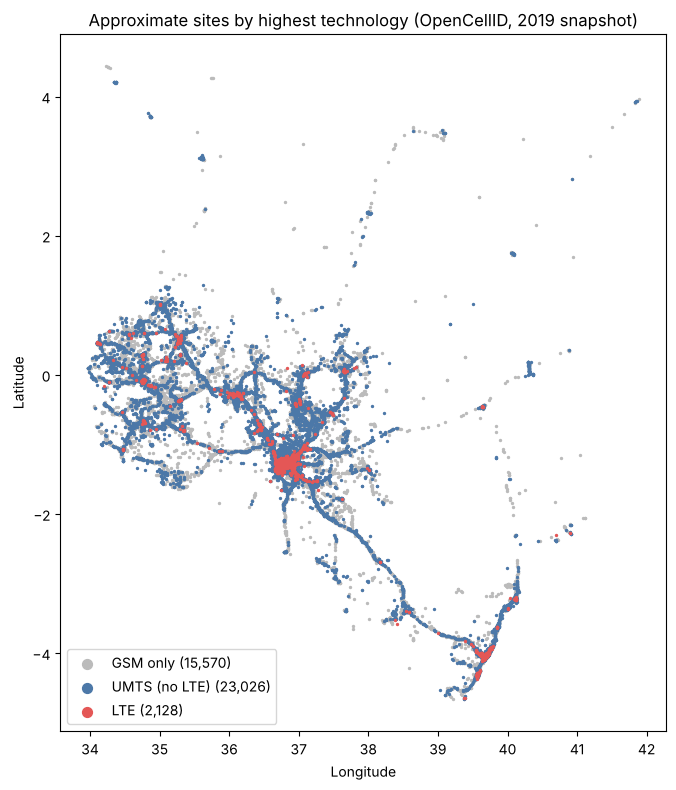

In [6]:
# Group the cells by site; 'g' is reused several times below.
g = cells.groupby('site_id')
# Named aggregation: new_column=(source_column, function), giving one row per site.
# 'size' counts the cells of each site. lambda x: x.mode()[0] is a small unnamed function that
# returns the most frequent value (mode() sorts tied values, and [0] takes the first).
sites = g.agg(lat=('lat', 'mean'), lon=('lon', 'mean'), n_cells=('cell', 'size'),
              county=('county', lambda x: x.mode()[0]), subcounty=('subcounty', lambda x: x.mode()[0]),
              mean_samples=('samples', 'mean'))
# For each technology r, count that site's cells of type r: (x == r) is True/False per cell
# and .sum() counts the Trues. This creates the columns n_GSM, n_UMTS and n_LTE; the result is
# indexed by site_id, so it lines up with the rows of 'sites'.
for r in ['GSM', 'UMTS', 'LTE']:
    sites['n_' + r] = g['radio'].apply(lambda x: (x == r).sum())
# Number of different operators with cells at the site (a shared mast has more than one).
sites['n_operators'] = g['operator'].nunique()
# np.select(conditions, choices, default) picks the first true condition for each site:
# any LTE cell -> 'LTE'; else any UMTS cell -> 'UMTS (no LTE)'; else 'GSM only'.
# (sites.n_LTE is a shortcut for sites['n_LTE'].)
sites['tech'] = np.select([sites.n_LTE > 0, sites.n_UMTS > 0], ['LTE', 'UMTS (no LTE)'], 'GSM only')

print(f"Logical cells: {len(cells):,} -> approximate sites: {len(sites):,}")
# value_counts() counts the sites per label; to_frame('sites') shows it as a one-column table.
display(sites['tech'].value_counts().to_frame('sites'))

# Figure 4.2: one scatter layer per technology, each with its own colour and legend label.
# The list holds (label, colour) pairs, which the loop unpacks into t and col.
fig, ax = plt.subplots(figsize=(7, 8))
for t, col in [('GSM only', '#bbbbbb'), ('UMTS (no LTE)', '#4c78a8'), ('LTE', '#e45756')]:
    # Boolean mask: keep only the sites whose highest technology is t.
    s = sites[sites.tech == t]
    # s=2 is the dot size; the legend label shows the number of sites in the group.
    ax.scatter(s.lon, s.lat, s=2, c=col, label=f"{t} ({len(s):,})")
ax.set_title('Approximate sites by highest technology (OpenCellID, 2019 snapshot)')
# markerscale=5 enlarges the legend dots. set_aspect('equal') draws a degree of latitude and a
# degree of longitude at the same length; near the equator they are almost equal on the ground.
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.legend(markerscale=5); ax.set_aspect('equal')
plt.tight_layout()
save_figure('4.02', 'sites_by_technology'); plt.show()

**How to read the output.** The first line compares cells with sites; their ratio is the mean cells per site in the "(used)" row of Table 4.2. The small table counts sites by highest technology: *UMTS (no LTE)* and *GSM only* sites have no 4G, so they are the upgrade candidates of Step 2. In Figure 4.2 each dot is a site and the legend gives each group's size. There is no background map, so the outline of Kenya is drawn by the sites themselves: dense clusters mark towns, and empty areas have few recorded sites, either because few people live there or because the registry is thin (Step 6).

## Step 6: Coverage of the Registry by Sub-County
Sub-counties with very few recorded sites are likely to be **under-recorded** (crowdsourced data are thin in remote areas), not necessarily unserved. They are flagged in Notebook 03 as `sparse_infrastructure` and treated with caution in the final ranking.

**Why it matters.** If the registry misses sites, the capacity proxy is too low and the load-to-capacity ratio too high, so a sub-county could look stressed when it is not. `sites.groupby('subcounty').size()` counts the sites per sub-county (a site belongs to the most common sub-county among its cells), and the code counts those below `SPARSE_SITES` (5, set in `project_config.py`).

In [7]:
# Number of sites in each sub-county: a pandas Series indexed by sub-county name.
sites_per_sc = sites.groupby('subcounty').size()
print(f"Sub-counties with at least one site: {len(sites_per_sc)}")
# ':.0f' prints a number with no decimal places.
print(f"Sites per sub-county: median {sites_per_sc.median():.0f}, min {sites_per_sc.min()}, max {sites_per_sc.max()}")
# (sites_per_sc < SPARSE_SITES) is True/False per sub-county; .sum() counts the Trues.
print(f"Sub-counties with fewer than {SPARSE_SITES} recorded sites: {(sites_per_sc < SPARSE_SITES).sum()}")
# The ten sub-counties with the fewest recorded sites: sort from smallest, keep the first 10.
display(sites_per_sc.sort_values().head(10).to_frame('recorded sites'))

Sub-counties with at least one site: 294
Sites per sub-county: median 70, min 1, max 1829
Sub-counties with fewer than 5 recorded sites: 23


,recorded sites
subcounty,
Hulugho Sub County,1
Pokot Central Sub County,1
Loima Sub County,1
LAFEY,1
Mt Elgon Sub County,1
Merti Sub County,1
Marakwet East sub-county,1
MANDERA WEST,1
Tarbaj Sub County,1


**How to read the output.** The first count should equal the 294 sub-counties of Step 1; a smaller number would mean some sub-county's cells all sit in sites assigned to a neighbour. The median is shown rather than the mean because such counts are usually skewed by a few large urban sub-counties; comparing it with the maximum shows how uneven the spread is. Sub-counties below `SPARSE_SITES` are the ones flagged in Notebook 03, and the table lists the ten with the fewest sites (names as spelled in the registry).

## Step 7: Export and Hand-Off to Notebook 03
Two files are saved to `Data/processed/`:
- `cells_clean.parquet`: one row per cleaned logical cell, with the new `site_id` and `operator` columns, kept for inspection.
- `sites_all_technologies.csv`: one row per site (`site_id`, `lat`, `lon`, `n_cells`, `county`, `subcounty`, `mean_samples`, `n_GSM`, `n_UMTS`, `n_LTE`, `n_operators`, `tech`). Notebook 03 reads it to assign Ookla tiles and build capacity; Notebook 05 reads it for candidate sites.

**Parquet** is a compact binary table format that stores each column's data type and reads faster than CSV, but needs a library such as pandas (with `pyarrow`) to open. `reset_index()` turns `site_id`, which became the index during the `groupby`, back into an ordinary column so it is written to the CSV.

In [8]:
# Save the cleaned cells (with site_id and operator) as Parquet. index=False leaves out the
# pandas row labels, which are not needed later.
cells.to_parquet(PROCESSED + 'cells_clean.parquet', index=False)
# reset_index() turns the site_id index into a normal column, so it is saved in the CSV.
sites.reset_index().to_csv(PROCESSED + 'sites_all_technologies.csv', index=False)
print(f"[saved] {PROCESSED}cells_clean.parquet ({len(cells):,} cells with site_id and operator)")
print(f"[saved] {PROCESSED}sites_all_technologies.csv ({len(sites):,} sites)")

[saved] Data/processed/cells_clean.parquet (78,722 cells with site_id and operator)
[saved] Data/processed/sites_all_technologies.csv (40,724 sites)


### Summary of Notebook 01
- The registry gives a usable national infrastructure layer of GSM, UMTS and LTE cells grouped into approximate sites. It has **no 5G cells** and is a **2019 snapshot**. One sub-county name was harmonised, which leaves 294 sub-counties with recorded cells.
- Complete-linkage clustering keeps every pair of cells in an approximate site within 100 m (the threshold chosen for this study; alternatives in Table 4.2). Single linkage would have merged cells across several Nairobi sub-counties (Table 4.2).
- **Next:** Notebook 02 prepares the time dimension (CA national telemetry and Ookla demand), and Notebook 03 joins both onto this layer.

**Design choices to be ready to explain:** removing cells outside the border while only reporting location confidence (Step 1, a declared deviation); keeping all radio technologies although the study is about 5G (Step 2); treating the 2019 infrastructure as a static baseline (Step 3); complete linkage at 100 m rather than grid snapping or single linkage (Step 4); flagging sparsely recorded sub-counties rather than trusting them at face value (Step 6).